# 7. Beyond the ground state: excitations and dynamics

**Goal.** Experiments rarely measure a ground-state energy. Neutrons, light and quenches see *excitations*: gaps,
how a disturbance spreads, the spectrum $S(k, \omega)$. This notebook gets them from MPS. First the lowest excited
state, by running DMRG again with the ground state pushed up. Then real-time evolution with TEBD, which is a DMRG
sweep with "find the lowest eigenvector" replaced by "multiply by a gate". With it we follow a quench, see why
entanglement growth sets a time limit, and compute the dynamical structure factor. Every number is checked against
the free-fermion solution of the TFIM, $H = -\sum_i X_iX_{i+1} - h\sum_i Z_i$.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import dmrg_from_scratch as dmrg

Zop = np.diag([1.0, -1.0])
RESULTS = Path("..") / "results"

## 1. The first excited state

**Recipe.** Find the ground state $|\psi_0\rangle$. Then run DMRG on

$$H' = H + w\,|\psi_0\rangle\langle\psi_0|,$$

with the penalty $w$ larger than the gap. Every state orthogonal to $|\psi_0\rangle$ has the same energy under $H'$
as under $H$, and $|\psi_0\rangle$ itself is pushed up by $w$, so the ground state of $H'$ is the first excited state
of $H$. In the two-site update the projector becomes $w|p\rangle\langle p|$, where $p$ is $|\psi_0\rangle$ seen
through the current left and right isometries (an overlap environment, built like $L$ and $R$ but with
$|\psi_0\rangle$ in place of the MPO). `dmrg_excited` is the sweep of notebook 3 with that one extra term.

**Exact answer.** The TFIM is a free-fermion model, $H = \sum_n \Lambda_n (n_n - \tfrac12)$, so the first excited
state puts one fermion in the cheapest mode: $E_1 - E_0 = \Lambda_\text{min}$.

In [2]:
L, h = 24, 1.5
mpo = dmrg.tfim_mpo(L, h)
g = dmrg.dmrg(mpo, chi_max=32, n_sweeps=4)
e = dmrg.dmrg_excited(mpo, chi_max=32, lower=[g["mps"]], n_sweeps=6)
gap_exact = dmrg.tfim_open_gap(L, h)
print(f"DMRG gap  = {e['energy'] - g['energy']:.10f}")
print(f"exact gap = {gap_exact:.10f}   (infinite chain: 2|h - 1| = {2 * abs(h - 1):.3f})")
print(f"overlap with the ground state: {e['overlaps'][0]:.1e}")

DMRG gap  = 1.0399664983
exact gap = 1.0399664983   (infinite chain: 2|h - 1| = 1.000)
overlap with the ground state: 2.1e-15


The gap is close to $2|h - J|$, the gap of the infinite chain (the bottom of the dispersion
$\varepsilon(q) = 2\sqrt{J^2 + h^2 - 2Jh\cos q}$ at $q = 0$; Pfeuty, Ann. Phys. 57, 79 (1970)); the open chain of
24 sites is a little above it because the lowest mode cannot have $q$ exactly 0.

In the ordered phase $h < 1$ the same call finds a "gap" of almost zero: the open chain has two nearly degenerate
ground states (the two directions of the magnetization, split by an amount exponentially small in $L$).

In [3]:
mpo_o = dmrg.tfim_mpo(L, 0.5)
g_o = dmrg.dmrg(mpo_o, chi_max=32, n_sweeps=4)
e_o = dmrg.dmrg_excited(mpo_o, chi_max=32, lower=[g_o["mps"]], n_sweeps=6)
print(f"h = 0.5: DMRG gap = {e_o['energy'] - g_o['energy']:.2e}, exact = {dmrg.tfim_open_gap(L, 0.5):.2e}")

h = 0.5: DMRG gap = 8.94e-08, exact = 8.94e-08


## 2. Real time: TEBD

**Recipe.** Split $H = \sum_b h_b$ into two-site terms on the bonds $b = (i, i+1)$ (each field $-hZ_i$ shared between
the two bonds that touch site $i$). Each $e^{-i\,\delta t\, h_b}$ is a $4\times4$ gate. A time step is a sweep:

1. contract sites $b, b+1$ into $\theta$, apply the gate for $\delta t/2$,
2. split $\theta$ with a truncated SVD, keeping at most $\chi$ Schmidt values, move one bond right,
3. at the right end, come back with the same half-step gates.

The product of gates $U_0 U_1\cdots U_{L-2}U_{L-2}\cdots U_1U_0$ is symmetric, so the error of a step is
$O(\delta t^3)$ and the error at a fixed time is $O(\delta t^2)$ (second-order Trotter; Vidal,
[arXiv:quant-ph/0310089](https://arxiv.org/abs/quant-ph/0310089); White and Feiguin,
[arXiv:cond-mat/0403310](https://arxiv.org/abs/cond-mat/0403310)). The truncated SVD is the only other
approximation.

**A quench.** Start from all spins up, $|{\uparrow\uparrow\cdots}\rangle$ (the ground state at $h = \infty$), and
evolve with $h = 1.5$. The exact answer comes from free fermions: in terms of Majorana operators $a_m$, the
Heisenberg equation is linear, $\dot a = Ma$, so $a(t) = e^{Mt}a$ and every two-point function rotates with
$e^{Mt}$ (`dmrg.tfim_quench`; the derivation is in the comments of `exact.py`, checked against dense ED in
`tests/test_dynamics.py`).

largest error in <Z_mid(t)>: 0.00047645141854568696


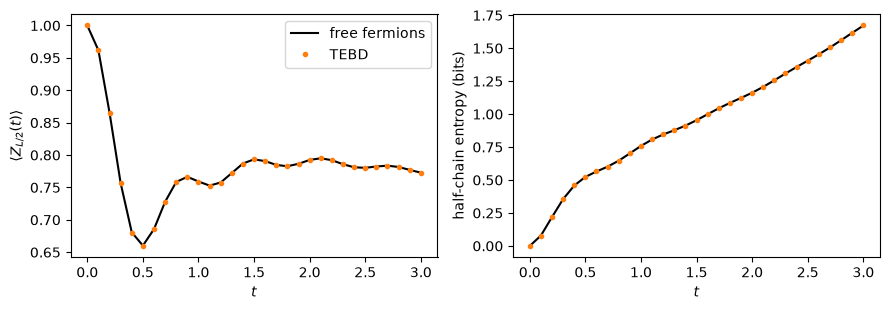

In [4]:
L, h, dt, chi = 24, 1.5, 0.05, 64
mps = [A.astype(complex) for A in dmrg.product_mps([np.array([1.0, 0.0])] * L)]
half = dmrg.gates(dmrg.tfim_bond_hamiltonians(L, h), dt / 2)
ts, z_mid, S = [], [], []
for k in range(61):  # t up to 3
    if k % 2 == 0:
        ts.append(k * dt)
        z_mid.append(dmrg.local_expectations(mps, Zop)[L // 2])
        S.append(dmrg.half_chain_entropy(mps))
    if k < 60:
        dmrg.tebd_step(mps, half, chi)
ts = np.array(ts)
ex = dmrg.tfim_quench(L, h, ts)
print("largest error in <Z_mid(t)>:", np.max(np.abs(np.array(z_mid) - ex["z"][:, L // 2])))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(ts, ex["z"][:, L // 2], "k-", label="free fermions")
ax[0].plot(ts, z_mid, "C1o", ms=3, label="TEBD")
ax[0].set(xlabel="$t$", ylabel=r"$\langle Z_{L/2}(t)\rangle$")
ax[0].legend()
ax[1].plot(ts, ex["entropy"], "k-")
ax[1].plot(ts, S, "C1o", ms=3)
ax[1].set(xlabel="$t$", ylabel="half-chain entropy (bits)")
fig.tight_layout()

The magnetization relaxes from 1 to a plateau with damped oscillations, and TEBD follows it to the Trotter error
$\sim\delta t^2$ (Exercise 1). The right panel is the problem: the entanglement grows **linearly** in time.
Pairs of quasiparticles are created everywhere at $t = 0$ and fly apart; a pair with one partner on each side of
the cut adds entanglement, and the number of such pairs grows linearly with $t$ until it saturates at a value
proportional to the size of the region (Calabrese and Cardy,
[arXiv:cond-mat/0503393](https://arxiv.org/abs/cond-mat/0503393); J. Stat. Mech. P04010 (2005)).

## 3. Why time is hard: the entanglement barrier

An MPS with bond dimension $\chi$ holds at most $\log_2\chi$ bits across a cut. If $S(t)$ grows linearly, then
$\chi$ must grow **exponentially** in time. Run the same quench at small bond dimensions:

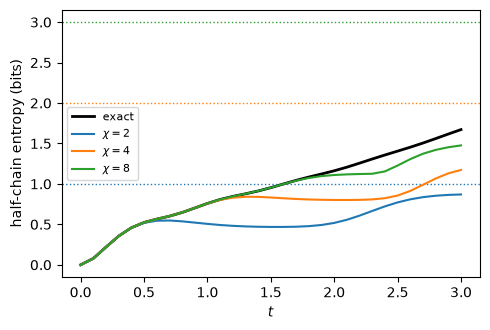

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(ts, ex["entropy"], "k-", lw=2, label="exact")
for chi_small in [2, 4, 8]:
    mps = [A.astype(complex) for A in dmrg.product_mps([np.array([1.0, 0.0])] * L)]
    S_small = []
    for k in range(61):
        if k % 2 == 0:
            S_small.append(dmrg.half_chain_entropy(mps))
        if k < 60:
            dmrg.tebd_step(mps, half, chi_small)
    (line,) = ax.plot(ts, S_small, label=rf"$\chi = {chi_small}$")
    ax.axhline(np.log2(chi_small), color=line.get_color(), ls=":", lw=1)
ax.set(xlabel="$t$", ylabel="half-chain entropy (bits)")
ax.legend(fontsize=8)
fig.tight_layout()

Each truncated run follows the exact curve, then flattens out well below its ceiling $\log_2\chi$ (dotted): the
truncation starts to bite as soon as the discarded Schmidt values are no longer negligible, before the ceiling is
reached. From then on its observables drift away from the exact ones. The full run, 64 spins up to $t = 12$, from `results/quench_entropy.json`
(`python scripts/make_results.py quench_entropy`, about a minute on 4 cores):

chi =   4: error in <Z> passes 1e-3 at t = 1.1
chi =   8: error in <Z> passes 1e-3 at t = 1.7
chi =  16: error in <Z> passes 1e-3 at t = 2.5
chi =  64: error in <Z> passes 1e-3 at t = 4.3


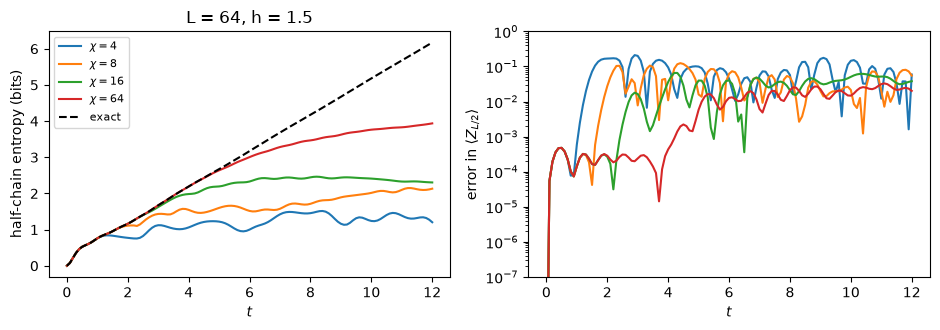

In [6]:
q = json.loads((RESULTS / "quench_entropy.json").read_text())
Lq, hq = q["L"], q["h"]
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for run in q["runs"]:
    t = np.array(run["t"])
    ax[0].plot(t, run["S"], label=rf"$\chi = {run['chi']}$")
    exq = dmrg.tfim_quench(Lq, hq, t)
    ax[1].semilogy(t, np.abs(np.array(run["z_mid"]) - exq["z"][:, Lq // 2]) + 1e-12, label=rf"$\chi = {run['chi']}$")
ax[0].plot(t, exq["entropy"], "k--", label="exact")
ax[0].set(xlabel="$t$", ylabel="half-chain entropy (bits)", title=f"L = {Lq}, h = {hq}")
ax[1].set(xlabel="$t$", ylabel=r"error in $\langle Z_{L/2}\rangle$", ylim=(1e-7, 1))
ax[0].legend(fontsize=8)
fig.tight_layout()
for run in q["runs"]:
    t = np.array(run["t"])
    err = np.abs(np.array(run["z_mid"]) - exq["z"][:, Lq // 2])
    bad = t[err > 1e-3]
    print(f"chi = {run['chi']:3d}: error in <Z> passes 1e-3 at t = " + (f"{bad[0]:.1f}" if len(bad) else "never"))

Doubling $\chi$ buys a roughly fixed extra stretch of time, here about 0.6 to 0.9 time units per doubling, not
twice the time. Reaching twice as far needs the bond dimension squared: that is the exponential wall of real-time
evolution, the same area-law argument as in notebook 0 but now in time instead of system width. Global
quenches like this one are the hardest case. Near equilibrium (a local disturbance on top of a ground state, which
is what a scattering experiment probes) entanglement grows much more slowly, and that is where MPS dynamics shines.

## 4. What experiments see: the dynamical structure factor

A neutron scatters off a spin and transfers momentum $k$ and energy $\omega$; the rate is the dynamical structure
factor

$$S(k, \omega) = \sum_r e^{-ikr}\int dt\, e^{i\omega t}\, C(r, t),\qquad
C(r, t) = \langle Z_{c+r}(t)\,Z_c(0)\rangle - \langle Z_{c+r}\rangle\langle Z_c\rangle .$$

**Recipe.** (1) DMRG ground state $|\psi_0\rangle$. (2) Kick it: $|\phi\rangle = Z_c|\psi_0\rangle$ on the middle
site. (3) Evolve $|\phi\rangle$ and $|\psi_0\rangle$ with the same gates and read
$\langle\psi_0(t)|Z_j|\phi(t)\rangle$ on every site $j$ at once (evolving $|\psi_0\rangle$ too, instead of
multiplying by $e^{iE_0t}$, cancels the Trotter error in its phase). (4) Fourier transform in $r$ and $t$, with a
Gaussian window so the cut at $t_\text{max}$ does not ring. Only the kicked region is entangled, so this needs far
less bond dimension than the global quench.

In [7]:
L, h, dt, chi = 24, 1.5, 0.05, 24
g = dmrg.dmrg(dmrg.tfim_mpo(L, h), chi_max=chi, n_sweeps=4)
half = dmrg.gates(dmrg.tfim_bond_hamiltonians(L, h), dt / 2)
steps, C = dmrg.dynamical_correlations(g["mps"], Zop, L // 2, half, n_steps=80, chi_max=chi, every=2)
C_exact = dmrg.tfim_zz_dynamics(L, h, L // 2, steps * dt)
print(f"largest error in C(r, t), t <= 4: {np.max(np.abs(C - C_exact)):.1e}  (largest |C| = {np.max(np.abs(C_exact)):.2f})")

largest error in C(r, t), t <= 4: 4.6e-04  (largest |C| = 0.23)


**Exact answer.** $Z_i = -i\,a_{2i}a_{2i+1}$ is quadratic in fermions, so $Z$ acting on the ground state creates
exactly two quasiparticles. With momenta $q$ and $k - q$ they cost $\varepsilon(q) + \varepsilon(k - q)$, so
$S^{zz}(k,\omega)$ is a **two-particle continuum** between

$$\omega_\text{min}(k) = \min_q[\varepsilon(q) + \varepsilon(k-q)],\qquad
\omega_\text{max}(k) = \max_q[\varepsilon(q) + \varepsilon(k-q)].$$

The full run, 64 spins to $t = 14$ at $\chi = 48$, from `results/zz_spectrum.json`
(`python scripts/make_results.py zz_spectrum`, a few minutes), next to the same transform of the free-fermion
$C(r, t)$:

TEBD vs free fermions: largest error in C(r, t) = 4.6e-04


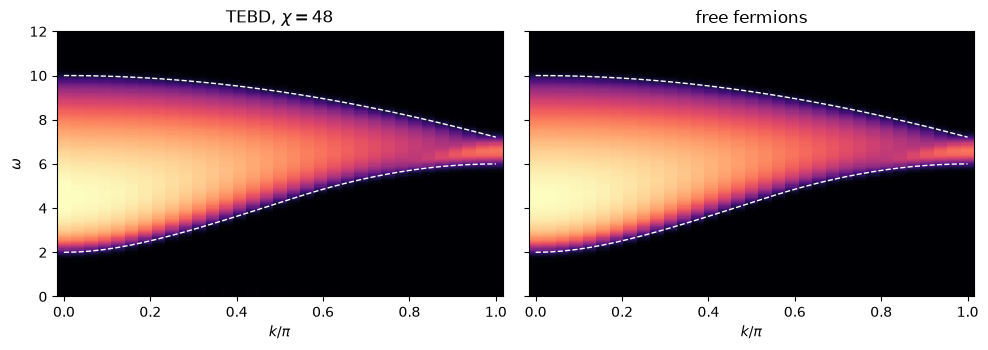

In [8]:
s = json.loads((RESULTS / "zz_spectrum.json").read_text())
ks, om, S_tebd = np.array(s["ks"]), np.array(s["omegas"]), np.array(s["S"])
times = np.arange(0, s["t_max"] + 1e-9, 0.1)
C_ff = dmrg.tfim_zz_dynamics(s["L"], s["h"], s["L"] // 2, times)
S_ff = dmrg.structure_factor(C_ff, 0.1, s["L"] // 2, ks, om)
print(f"TEBD vs free fermions: largest error in C(r, t) = {s['max_error_C']:.1e}")

q = np.linspace(-np.pi, np.pi, 801)
eps = lambda q: 2 * np.sqrt(1 + s["h"] ** 2 - 2 * s["h"] * np.cos(q))  # noqa: E731
lo = [np.min(eps(q) + eps(k - q)) for k in ks]
hi = [np.max(eps(q) + eps(k - q)) for k in ks]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
vmax = S_ff.max()
for a, S_, title in [(ax[0], S_tebd, f"TEBD, $\\chi = {s['chi']}$"), (ax[1], S_ff, "free fermions")]:
    a.pcolormesh(ks / np.pi, om, S_.T, shading="auto", cmap="magma", vmin=0, vmax=vmax)
    a.plot(ks / np.pi, lo, "w--", lw=1)
    a.plot(ks / np.pi, hi, "w--", lw=1)
    a.set(xlabel=r"$k/\pi$", title=title)
ax[0].set(ylabel=r"$\omega$", ylim=(0, 12))
fig.tight_layout()

The weight fills the band between the dashed lines, the two-particle continuum, with the same shape in both
panels; the blur at the edges is the frequency resolution $\sim 1/t_\text{max}$ of the finite time window. The
continuum starts at $\omega_\text{min}(0) = 2\Delta$, twice the single-particle gap of Section 1: $Z$ cannot make one
quasiparticle alone.

**In a real material.** CoNb$_2$O$_6$ is a quasi-one-dimensional Ising ferromagnet. Coldea *et al.* tuned it
through its critical point with a strong transverse field and measured the spin excitations by neutron
scattering. Near the critical field they found two sharp low-energy modes whose energy ratio approaches the golden
mean, as predicted for the first two particles of the $E_8$ spectrum, which appears when the critical Ising chain
feels a small longitudinal field (here from the couplings between chains) ([arXiv:1103.3694](https://arxiv.org/abs/1103.3694);
[Science 327, 177 (2010)](https://doi.org/10.1126/science.1180085)). The pure TFIM above has no such bound
states, and once a longitudinal field is added it is no longer free fermions. TEBD does not care: Exercise 4 adds
the field.

## Exercises

1. Run the quench of Section 2 with $\delta t = 0.1, 0.05, 0.025$ and plot the error at $t = 4$ against $\delta t$.
   Check that it falls as $\delta t^2$. What happens with a first-order step (apply each gate once with the full
   $\delta t$, left to right only)?
2. Find the second excited state by passing two lower states to `dmrg_excited`. Compare with the exact
   $E_0 + \Lambda_2$ (`dmrg.tfim_single_particle_energies`). Why is it not $E_0 + 2\Lambda_1$?
3. Quench from all up into the ordered phase, $h = 0.5$. Does the entanglement still grow linearly? Does
   $\langle Z\rangle$ settle?
4. Add a longitudinal field, $-g\sum_i X_i$, to the bond Hamiltonians (share it between bonds like the transverse
   field). With $g = 0.05$ near $h = 1$, compute $C^{xx}(r, t)$ (use $X$ instead of $Z$) and its $S(k = 0,
   \omega)$. Look for sharp peaks below the continuum, and compare the ratio of the two lowest with the golden mean
   1.618.
5. In Section 4, lower $\chi$ to 8 and then 4. Which part of $S(k, \omega)$ goes wrong first, and why does the
   local kick need so much less bond dimension than the global quench?